# Markdown Decision Engine

## 1. Load Required Data and Artifacts

### Objective
Load the historical retail data, final demand model, SKU cluster mapping,
price-response information and uncertainty parameters required to simulate
markdown scenarios.

### Decision Engine Role
The decision engine does not train another machine-learning model.

Instead, it combines:
- baseline demand forecasting
- historical price-response behaviour
- prediction uncertainty
- inventory position
- profitability calculations
- business constraints

to recommend an appropriate markdown level.

In [1]:
import pandas as pd
import numpy as np
import joblib

# ---------------------------------------------------------
# Load Full Historical Dataset
# ---------------------------------------------------------

raw_path = (
    "../data/raw/"
    "SmartMarkdown_Data_Dev_2024_2025.xlsx"
)

df = pd.read_excel(raw_path)

df["Week_Start"] = pd.to_datetime(
    df["Week_Start"]
)

# ---------------------------------------------------------
# Load Final Demand Model
# ---------------------------------------------------------

demand_model = joblib.load(
    "../models/"
    "smartmarkdown_demand_model.joblib"
)

# ---------------------------------------------------------
# Load Model Metadata
# ---------------------------------------------------------

model_metadata = joblib.load(
    "../models/"
    "smartmarkdown_demand_model_metadata.joblib"
)

# ---------------------------------------------------------
# Load SKU Cluster Mapping
# ---------------------------------------------------------

cluster_mapping = pd.read_csv(
    "../data/processed/"
    "smartmarkdown_sku_cluster_mapping.csv"
)

print("Historical Data Shape:", df.shape)
print("Unique SKUs:", df["SKU_ID"].nunique())

print("\nFinal Demand Model Loaded")
print("Target:", model_metadata["target"])
print("Feature Count:", model_metadata["feature_count"])

print("\nCluster Mapping Shape:", cluster_mapping.shape)

Historical Data Shape: (4200, 30)
Unique SKUs: 40

Final Demand Model Loaded
Target: Future_Latent_Demand
Feature Count: 33

Cluster Mapping Shape: (40, 3)


In [3]:
price_response_df = pd.read_csv(
    "../data/processed/"
    "smartmarkdown_price_response.csv"
)

print("Price Response Shape:",price_response_df.shape)

display(price_response_df.head())

Price Response Shape: (40, 8)


,SKU_ID,Demand_Per_1Pct_Discount,Discount_Demand_Corr,Cluster,Cluster_Label,Avg_Historical_Demand,Relative_Response_Per_1Pct,Relative_Response_Per_1Pct_Pct
0,SKU001,0.717576,0.734870,2,High-Demand Fast-Moving,66.561905,0.010781,1.078058
1,SKU002,0.718847,0.626153,2,High-Demand Fast-Moving,62.895238,0.011429,1.142928
2,SKU003,0.691383,0.824142,2,High-Demand Fast-Moving,44.895238,0.015400,1.539992
3,SKU004,0.623267,0.743742,2,High-Demand Fast-Moving,37.466667,0.016635,1.663525
4,SKU005,0.559624,0.770979,2,High-Demand Fast-Moving,39.800000,0.014061,1.406091


In [4]:
# ---------------------------------------------------------
# Price Response Adjustment
# ---------------------------------------------------------

def adjust_demand_for_discount(
    baseline_demand,
    current_discount,
    candidate_discount,
    relative_response_pct
):

    discount_change = (candidate_discount - current_discount)

    proportional_change = (discount_change * relative_response_pct / 100)

    adjusted_demand = (baseline_demand * (1 + proportional_change))

    return max(adjusted_demand, 0)

In [5]:
# ---------------------------------------------------------
# Adaptive 95% Prediction Interval
# ---------------------------------------------------------

def get_adaptive_prediction_interval(
    predicted_demand
):

    if predicted_demand <= 25:
        lower_residual = -5.53
        upper_residual = 9.25

    elif predicted_demand <= 50:
        lower_residual = -12.56
        upper_residual = 17.99

    else:
        lower_residual = -19.91
        upper_residual = 27.43

    lower_bound = max(predicted_demand + lower_residual,0)

    upper_bound = max(predicted_demand + upper_residual,0)

    return lower_bound, upper_bound

In [7]:
candidate_discounts = [
    0, 5, 8, 10, 12, 15,
    18, 20, 23, 25, 27, 30
]
print("Candidate Discounts:",candidate_discounts)

Candidate Discounts: [0, 5, 8, 10, 12, 15, 18, 20, 23, 25, 27, 30]


## 2. Sample SKU Scenario Setup

### Objective
Select one SKU and create its current decision state before simulating alternative
markdown levels.

The final demand model requires the same engineered features used during model
training. Therefore, the latest model-ready record is used to generate the
baseline next-week demand forecast.

This baseline forecast will then be adjusted across the candidate markdown
scenarios.

In [8]:
# ---------------------------------------------------------
# Load Model-Ready Feature Data
# ---------------------------------------------------------

feature_path = (
    "../data/processed/"
    "smartmarkdown_feature_engineered.csv"
)

feature_df = pd.read_csv(
    feature_path,
    parse_dates=["Week_Start"]
)

print("Feature Dataset Shape:", feature_df.shape)
print("Unique SKUs:", feature_df["SKU_ID"].nunique())

Feature Dataset Shape: (3840, 35)
Unique SKUs: 40


In [9]:
sample_sku = "SKU001"

sample_history = (
    feature_df[
        feature_df["SKU_ID"] == sample_sku
    ]
    .sort_values("Week_Start")
)

sample_row = sample_history.iloc[-1]

print("Sample SKU:", sample_sku)
print("Decision Week:", sample_row["Week_Start"])

Sample SKU: SKU001
Decision Week: 2025-12-22 00:00:00


In [10]:
display(
    sample_row[
        [
            "SKU_ID",
            "Category",
            "Discount_Pct",
            "Closing_Inventory",
            "Days_In_Inventory",
            "Sell_Through",
            "Future_Retail_Event",
            "Future_Season_Tag"
        ]
    ]
)

SKU_ID                        SKU001
Category                     Apparel
Discount_Pct                       0
Closing_Inventory                  4
Days_In_Inventory                 35
Sell_Through                     1.0
Future_Retail_Event    Year End Sale
Future_Season_Tag         All Season
Name: 95, dtype: object

In [11]:
current_raw_row = (
    df[
        (df["SKU_ID"] == sample_sku)
        &
        (df["Week_Start"] == sample_row["Week_Start"])
    ]
    .iloc[0]
)

print("MRP:", current_raw_row["MRP"])
print("Unit Cost:", current_raw_row["Unit_Cost"])
print("Current Selling Price:", current_raw_row["Selling_Price"])
print("Current Discount:", current_raw_row["Discount_Pct"], "%")
print("Closing Inventory:", current_raw_row["Closing_Inventory"])

MRP: 799
Unit Cost: 340
Current Selling Price: 799.0
Current Discount: 0 %
Closing Inventory: 4


In [12]:
feature_cols = model_metadata["features"]

X_sample = pd.DataFrame([sample_row[feature_cols]])

print("Model Input Shape:", X_sample.shape)

Model Input Shape: (1, 33)


In [13]:
baseline_demand = demand_model.predict(X_sample)[0]

print("Baseline Next-Week Demand Forecast:",round(baseline_demand, 2))

Baseline Next-Week Demand Forecast: 67.15


In [14]:
sample_response = (price_response_df[price_response_df["SKU_ID"] == sample_sku].iloc[0])

relative_response = (sample_response["Relative_Response_Per_1Pct_Pct"])

response_corr = (sample_response["Discount_Demand_Corr"])

cluster_label = (sample_response["Cluster_Label"])

print("Relative Response:",round(relative_response, 3),"% per discount point")

print("Discount-Demand Correlation:",round(response_corr, 3))

print("Cluster:",cluster_label)

Relative Response: 1.078 % per discount point
Discount-Demand Correlation: 0.735
Cluster: High-Demand Fast-Moving


## 3. Select a Representative Markdown Candidate

The initial sample SKU has only 4 units of closing inventory while forecast demand
is substantially higher.

This is a valid low-stock scenario where additional markdown is unlikely to provide
business value.

To demonstrate the markdown optimization logic more clearly, a SKU with sufficient
inventory relative to expected demand is selected for the first scenario simulation.

In [15]:
# ---------------------------------------------------------
# Latest Decision State for Every SKU
# ---------------------------------------------------------

latest_sku_rows = (
    feature_df
    .sort_values(["SKU_ID", "Week_Start"])
    .groupby("SKU_ID")
    .tail(1)
    .copy()
)

print("Latest SKU Records:", latest_sku_rows.shape[0])

Latest SKU Records: 40


In [16]:
# ---------------------------------------------------------
# Baseline Forecast for Latest State of Every SKU
# ---------------------------------------------------------

X_latest = latest_sku_rows[
    feature_cols
].copy()

latest_sku_rows["Baseline_Demand"] = (
    demand_model.predict(X_latest)
)

In [17]:
latest_sku_rows["Inventory_to_Demand"] = (
    latest_sku_rows["Closing_Inventory"]
    / latest_sku_rows["Baseline_Demand"]
)

In [18]:
markdown_candidates = (
    latest_sku_rows[
        [
            "SKU_ID",
            "Category",
            "Closing_Inventory",
            "Days_In_Inventory",
            "Sell_Through",
            "Discount_Pct",
            "Baseline_Demand",
            "Inventory_to_Demand"
        ]
    ]
    .sort_values("Inventory_to_Demand",ascending=False)
)

display(markdown_candidates.head(10))

,SKU_ID,Category,Closing_Inventory,Days_In_Inventory,Sell_Through,Discount_Pct,Baseline_Demand,Inventory_to_Demand
2975,SKU031,Accessories,113,14,0.216783,0,37.926067,2.979481
2303,SKU024,Footwear,107,14,0.272727,20,38.771536,2.759757
287,SKU003,Apparel,118,21,0.258065,0,44.163055,2.671917
3071,SKU032,Apparel,61,21,0.351648,25,24.375266,2.502537
2591,SKU027,Sports Equipment,56,14,0.232877,0,22.603427,2.477500
2687,SKU028,Sports Equipment,71,14,0.270833,0,29.655122,2.394190
3743,SKU039,Electronics,129,14,0.368687,25,54.773126,2.355170
2495,SKU026,Sports Equipment,25,14,0.324324,20,10.959906,2.281041
3263,SKU034,Accessories,62,14,0.371134,15,36.947232,1.678069
959,SKU010,Apparel,81,14,0.460993,25,49.193870,1.646547


## 4. Markdown Scenario Simulation

### Objective
Evaluate multiple candidate markdown levels for a selected SKU and estimate the
resulting demand, sales, revenue, profit and inventory impact.

### Scenario Logic
For each candidate discount:

1. Calculate the new selling price.
2. Adjust baseline demand using the SKU's historical markdown response.
3. Estimate demand uncertainty using the adaptive prediction interval.
4. Limit expected sales by available inventory.
5. Calculate revenue, gross profit and remaining inventory.

The resulting table forms the basis for markdown recommendation.

In [26]:
selected_sku = "SKU003"

In [27]:
selected_row = (latest_sku_rows[latest_sku_rows["SKU_ID"] == selected_sku].iloc[0])

selected_raw_row = (
    df[
        (df["SKU_ID"] == selected_sku)
        &
        (df["Week_Start"] == selected_row["Week_Start"])
    ]
    .iloc[0]
)

selected_response = (
    price_response_df[price_response_df["SKU_ID"] == selected_sku]
    .iloc[0]
)

In [28]:
print("Selected SKU:", selected_sku)
print("Category:", selected_row["Category"])

print("Baseline Demand:",
round(selected_row["Baseline_Demand"], 2))

print("Closing Inventory:",selected_raw_row["Closing_Inventory"])

print("Current Discount:",selected_raw_row["Discount_Pct"],"%")

print("MRP:",selected_raw_row["MRP"])

print("Unit Cost:",selected_raw_row["Unit_Cost"])

print("Relative Markdown Response:",round(selected_response["Relative_Response_Per_1Pct_Pct"],3),"%")

Selected SKU: SKU003
Category: Apparel
Baseline Demand: 44.16
Closing Inventory: 118
Current Discount: 0 %
MRP: 1999
Unit Cost: 940
Relative Markdown Response: 1.54 %


In [32]:
scenario_results = []

baseline_demand = selected_row["Baseline_Demand"]

current_discount = selected_raw_row["Discount_Pct"]

mrp = selected_raw_row["MRP"]

unit_cost = selected_raw_row["Unit_Cost"]

available_inventory = selected_raw_row["Closing_Inventory"]

relative_response = selected_response[
    "Relative_Response_Per_1Pct_Pct"
]

**Inventory Assumption:** Current closing inventory is treated as the stock
available for the next-week markdown decision. No additional replenishment is
assumed during the scenario simulation.

In [33]:
for candidate_discount in candidate_discounts:

    # Candidate selling price
    selling_price = (mrp * (1 - candidate_discount / 100))

    # Demand adjusted for candidate markdown
    adjusted_demand = adjust_demand_for_discount(
        baseline_demand=baseline_demand,
        current_discount=current_discount,
        candidate_discount=candidate_discount,
        relative_response_pct=relative_response
    )

    # Prediction uncertainty
    lower_demand, upper_demand = (get_adaptive_prediction_interval(adjusted_demand))

    # Inventory-constrained expected sales
    expected_units_sold = min(adjusted_demand,available_inventory)

    # Financial outcomes
    revenue = (expected_units_sold * selling_price)

    gross_profit = (expected_units_sold * (selling_price - unit_cost))

    margin_pct = (
        ((selling_price - unit_cost) / selling_price) * 100
        if selling_price > 0
        else 0
    )

    leftover_inventory = max(available_inventory - expected_units_sold,0)

    scenario_results.append({
        "Candidate_Discount": candidate_discount,
        "Selling_Price": selling_price,
        "Adjusted_Demand": adjusted_demand,
        "Demand_Lower": lower_demand,
        "Demand_Upper": upper_demand,
        "Expected_Units_Sold": expected_units_sold,
        "Revenue": revenue,
        "Gross_Profit": gross_profit,
        "Margin_Pct": margin_pct,
        "Leftover_Inventory": leftover_inventory
    })

# ---------------------------------------------------------
# Create Markdown Scenario Table
# ---------------------------------------------------------

scenario_df = pd.DataFrame(
    scenario_results
)

display(
    scenario_df.round(2)
)

,Candidate_Discount,Selling_Price,Adjusted_Demand,Demand_Lower,Demand_Upper,Expected_Units_Sold,Revenue,Gross_Profit,Margin_Pct,Leftover_Inventory
0,0,1999.00,44.16,31.60,62.15,44.16,88281.95,46768.68,52.98,73.84
1,5,1899.05,47.56,35.00,65.55,47.56,90325.64,45615.86,50.50,70.44
2,8,1839.08,49.60,37.04,67.59,49.60,91225.57,44597.89,48.89,68.40
3,10,1799.10,50.96,31.05,78.39,50.96,91689.57,43783.28,47.75,67.04
4,12,1759.12,52.32,32.41,79.75,52.32,92044.80,42859.92,46.56,65.68
5,15,1699.15,54.36,34.45,81.79,54.36,92373.73,41270.94,44.68,63.64
6,18,1639.18,56.40,36.49,83.83,56.40,92457.93,39437.24,42.65,61.60
7,20,1599.20,57.77,37.86,85.20,57.77,92378.12,38078.82,41.22,60.23
8,23,1539.23,59.81,39.90,87.24,59.81,92054.46,35837.27,38.93,58.19
9,25,1499.25,61.17,41.26,88.60,61.17,91702.74,34206.94,37.30,56.83


## 5. Scenario Decision Metrics

### Objective
Measure the trade-off between inventory reduction and profitability for each
markdown scenario.

Expected demand alone is not sufficient for selecting a markdown. A candidate
discount should improve inventory movement while maintaining acceptable
profitability and margin.

Additional decision metrics are therefore calculated for:

- projected sell-through
- inventory reduction
- profit retention
- conservative sales and profit using the lower demand bound

In [34]:
scenario_df["Projected_Sell_Through_Pct"] = (scenario_df["Expected_Units_Sold"]/ available_inventory* 100)

In [35]:
scenario_df["Inventory_Reduction_Pct"] = ((available_inventory - scenario_df["Leftover_Inventory"])/ available_inventory* 100)

In [36]:
base_profit = (scenario_df.loc[scenario_df["Candidate_Discount"] == current_discount,"Gross_Profit"].iloc[0])

scenario_df["Profit_Retention_Pct"] = (scenario_df["Gross_Profit"] / base_profit * 100)

In [37]:
scenario_df["Conservative_Units_Sold"] = np.minimum(scenario_df["Demand_Lower"],available_inventory)

scenario_df["Conservative_Revenue"] = (scenario_df["Conservative_Units_Sold"] * scenario_df["Selling_Price"])

scenario_df["Conservative_Gross_Profit"] = (scenario_df["Conservative_Units_Sold"] * (scenario_df["Selling_Price"] - unit_cost))

scenario_df["Conservative_Leftover_Inventory"] = (available_inventory - scenario_df["Conservative_Units_Sold"]).clip(lower=0)

In [39]:
decision_columns = [
    "Candidate_Discount",
    "Selling_Price",
    "Adjusted_Demand",
    "Demand_Lower",
    "Demand_Upper",
    "Projected_Sell_Through_Pct",
    "Leftover_Inventory",
    "Gross_Profit",
    "Profit_Retention_Pct",
    "Margin_Pct",
    "Conservative_Gross_Profit",
    "Conservative_Leftover_Inventory"
]

display(scenario_df[decision_columns].round(2))

,Candidate_Discount,Selling_Price,Adjusted_Demand,Demand_Lower,Demand_Upper,Projected_Sell_Through_Pct,Leftover_Inventory,Gross_Profit,Profit_Retention_Pct,Margin_Pct,Conservative_Gross_Profit,Conservative_Leftover_Inventory
0,0,1999.00,44.16,31.60,62.15,37.43,73.84,46768.68,100.00,52.98,33467.64,86.40
1,5,1899.05,47.56,35.00,65.55,40.31,70.44,45615.86,97.54,50.50,33570.20,83.00
2,8,1839.08,49.60,37.04,67.59,42.04,68.40,44597.89,95.36,48.89,33305.44,80.96
3,10,1799.10,50.96,31.05,78.39,43.19,67.04,43783.28,93.62,47.75,26678.60,86.95
4,12,1759.12,52.32,32.41,79.75,44.34,65.68,42859.92,91.64,46.56,26551.24,85.59
5,15,1699.15,54.36,34.45,81.79,46.07,63.64,41270.94,88.24,44.68,26156.26,83.55
6,18,1639.18,56.40,36.49,83.83,47.80,61.60,39437.24,84.32,42.65,25516.57,81.51
7,20,1599.20,57.77,37.86,85.20,48.95,60.23,38078.82,81.42,41.22,24954.15,80.14
8,23,1539.23,59.81,39.90,87.24,50.68,58.19,35837.27,76.63,38.93,23906.60,78.10
9,25,1499.25,61.17,41.26,88.60,51.84,56.83,34206.94,73.14,37.30,23072.27,76.74


## 6. Business Constraints and Recommendation Logic

### Objective
Identify markdown scenarios that improve inventory movement while protecting
profitability.

A markdown is not selected simply because it maximizes demand or minimizes
leftover inventory.

Each candidate scenario is evaluated against configurable business constraints
for:

- minimum margin
- minimum profit retention
- maximum permitted markdown
- conservative profitability under forecast uncertainty

Among feasible scenarios, the engine will select the markdown that provides the
best inventory improvement with the smallest necessary discount.

In [41]:
# ---------------------------------------------------------
# Conservative Profit Retention
# ---------------------------------------------------------

current_scenario = scenario_df[scenario_df["Candidate_Discount"] == current_discount].iloc[0]

base_conservative_profit = (current_scenario["Conservative_Gross_Profit"])

scenario_df["Conservative_Profit_Retention_Pct"] = (scenario_df["Conservative_Gross_Profit"] / base_conservative_profit * 100)

In [42]:
# ---------------------------------------------------------
# Configurable Business Constraints
# ---------------------------------------------------------

max_allowed_discount = 30

min_margin_pct = 35

min_profit_retention_pct = 80

min_conservative_profit_retention_pct = 75

In [43]:
scenario_df["Meets_Max_Discount"] = (scenario_df["Candidate_Discount"] <= max_allowed_discount)

scenario_df["Meets_Min_Margin"] = (scenario_df["Margin_Pct"] >= min_margin_pct)

scenario_df["Meets_Profit_Retention"] = (scenario_df["Profit_Retention_Pct"] >= min_profit_retention_pct)

scenario_df["Meets_Conservative_Profit"] = (scenario_df["Conservative_Profit_Retention_Pct"] >= min_conservative_profit_retention_pct)

scenario_df["Feasible"] = (
    scenario_df["Meets_Max_Discount"]
    &
    scenario_df["Meets_Min_Margin"]
    &
    scenario_df["Meets_Profit_Retention"]
    &
    scenario_df["Meets_Conservative_Profit"]
)

In [44]:
constraint_columns = [
    "Candidate_Discount",
    "Projected_Sell_Through_Pct",
    "Leftover_Inventory",
    "Gross_Profit",
    "Profit_Retention_Pct",
    "Conservative_Profit_Retention_Pct",
    "Margin_Pct",
    "Feasible"
]

display(scenario_df[constraint_columns].round(2))

,Candidate_Discount,Projected_Sell_Through_Pct,Leftover_Inventory,Gross_Profit,Profit_Retention_Pct,Conservative_Profit_Retention_Pct,Margin_Pct,Feasible
0,0,37.43,73.84,46768.68,100.00,100.00,52.98,True
1,5,40.31,70.44,45615.86,97.54,100.31,50.50,True
2,8,42.04,68.40,44597.89,95.36,99.52,48.89,True
3,10,43.19,67.04,43783.28,93.62,79.71,47.75,True
4,12,44.34,65.68,42859.92,91.64,79.33,46.56,True
5,15,46.07,63.64,41270.94,88.24,78.15,44.68,True
6,18,47.80,61.60,39437.24,84.32,76.24,42.65,True
7,20,48.95,60.23,38078.82,81.42,74.56,41.22,False
8,23,50.68,58.19,35837.27,76.63,71.43,38.93,False
9,25,51.84,56.83,34206.94,73.14,68.94,37.30,False


## 7. Final Markdown Selection Logic

### Objective
Select the smallest markdown that achieves a meaningful inventory improvement
while satisfying all profitability constraints.

### Selection Rule
1. Remove scenarios that violate margin or profit constraints.
2. Among feasible scenarios, identify those meeting the target sell-through.
3. Recommend the smallest discount that reaches the target.
4. If no feasible scenario reaches the target, select the feasible scenario with
   the highest projected sell-through.

This approach avoids unnecessary discounting and protects profit while still
addressing inventory pressure.

In [45]:
# ---------------------------------------------------------
# Configurable Inventory Objective
# ---------------------------------------------------------

target_sell_through_pct = 45

In [46]:
feasible_scenarios = (scenario_df[scenario_df["Feasible"]].copy())

print("Number of Feasible Scenarios:",len(feasible_scenarios))

Number of Feasible Scenarios: 7


In [47]:
target_scenarios = (
    feasible_scenarios[
        feasible_scenarios["Projected_Sell_Through_Pct"]
        >= target_sell_through_pct
    ]
    .copy()
)

display(
    target_scenarios[
        [
            "Candidate_Discount",
            "Projected_Sell_Through_Pct",
            "Profit_Retention_Pct",
            "Margin_Pct",
            "Leftover_Inventory"
        ]
    ].round(2)
)

,Candidate_Discount,Projected_Sell_Through_Pct,Profit_Retention_Pct,Margin_Pct,Leftover_Inventory
5,15,46.07,88.24,44.68,63.64
6,18,47.80,84.32,42.65,61.60


In [48]:
# ---------------------------------------------------------
# Select Recommended Markdown
# ---------------------------------------------------------

if not target_scenarios.empty:

    recommended_scenario = (target_scenarios.sort_values("Candidate_Discount").iloc[0])
    recommendation_reason = (
        "Smallest feasible markdown meeting "
        "the target sell-through."
    )

else:

    recommended_scenario = (
        feasible_scenarios
        .sort_values(
            [
                "Projected_Sell_Through_Pct",
                "Candidate_Discount"
            ],
            ascending=[False, True]
        )
        .iloc[0]
    )

    recommendation_reason = (
        "No feasible markdown reached the target "
        "sell-through; selected the feasible scenario "
        "with the highest projected sell-through."
    )

In [49]:
print("Recommended Discount:",recommended_scenario["Candidate_Discount"],"%")

print("Projected Sell Through:",round(recommended_scenario["Projected_Sell_Through_Pct"],2),"%")

print("Expected Gross Profit:",round(recommended_scenario["Gross_Profit"],2))

print("Profit Retention:",round(recommended_scenario["Profit_Retention_Pct"],2),"%")

print("Expected Leftover Inventory:",round(recommended_scenario["Leftover_Inventory"],2))

print("\nReason:",recommendation_reason)

Recommended Discount: 15 %
Projected Sell Through: 46.07 %
Expected Gross Profit: 41270.94
Profit Retention: 88.24 %
Expected Leftover Inventory: 63.64

Reason: Smallest feasible markdown meeting the target sell-through.


## 8. Reusable Markdown Recommendation Function

### Objective
Convert the single-SKU scenario logic into a reusable function that can generate
a markdown recommendation for any SKU.

The function will:

1. retrieve the latest SKU state,
2. generate the baseline demand forecast,
3. simulate all candidate discounts,
4. apply profitability constraints,
5. evaluate inventory improvement,
6. return the recommended markdown and supporting metrics.

In [115]:
def recommend_markdown(
    sku_id,
    latest_sku_rows,
    raw_df,
    price_response_df,
    demand_model,
    feature_cols,
    candidate_discounts,
    target_sell_through_pct=45,
    max_allowed_discount=30,
    min_margin_pct=35,
    min_profit_retention_pct=80,
    min_conservative_profit_retention_pct=75
):

    # -----------------------------------------------------
    # Retrieve SKU State
    # -----------------------------------------------------

    sku_match = latest_sku_rows[latest_sku_rows["SKU_ID"] == sku_id]

    if sku_match.empty:
        raise ValueError(f"{sku_id} not found in latest SKU data.")

    selected_row = sku_match.iloc[0]

    raw_match = raw_df[
        (raw_df["SKU_ID"] == sku_id)
        &
        (raw_df["Week_Start"] == selected_row["Week_Start"])
    ]

    if raw_match.empty:
        raise ValueError(f"Raw record not found for {sku_id}.")

    selected_raw_row = raw_match.iloc[0]

    response_match = price_response_df[price_response_df["SKU_ID"] == sku_id]

    if response_match.empty:
        raise ValueError(f"Price-response information not found for {sku_id}.")

    selected_response = response_match.iloc[0]

    # -----------------------------------------------------
    # Baseline Forecast
    # -----------------------------------------------------

    X_sku = pd.DataFrame([selected_row[feature_cols]])

    baseline_demand = (demand_model.predict(X_sku)[0])

    current_discount = (selected_raw_row["Discount_Pct"])

    mrp = selected_raw_row["MRP"]

    unit_cost = (selected_raw_row["Unit_Cost"])

    available_inventory = selected_raw_row["Closing_Inventory"]

# -----------------------------------------------------
# No-Inventory Edge Case
# -----------------------------------------------------

    if available_inventory <= 0:
        recommendation = {
            "SKU_ID": sku_id,
            "Baseline_Demand": baseline_demand,
            "Current_Discount": current_discount,
            "Recommended_Discount": np.nan,
            "Projected_Sell_Through_Pct": np.nan,
            "Expected_Gross_Profit": 0,
            "Profit_Retention_Pct": np.nan,
            "Margin_Pct": np.nan,
            "Expected_Leftover_Inventory": 0,
            "Reason": "No markdown action - no inventory available."
        }

        return recommendation, pd.DataFrame()
    
    relative_response = (selected_response["Relative_Response_Per_1Pct_Pct"])

    # available_inventory = (selected_raw_row["Closing_Inventory"])

    # relative_response = (selected_response["Relative_Response_Per_1Pct_Pct"])

    # ---------------------------------------------------------
    # Simulate Candidate Markdown Scenarios
    # ---------------------------------------------------------
    # For each candidate discount:
    # 1. Calculate the new selling price
    # 2. Adjust expected demand using historical price response
    # 3. Estimate lower and upper demand bounds
    # 4. Cap expected sales by available inventory
    # 5. Calculate revenue, profit, margin and leftover inventory
    # 6. Calculate conservative profit using the lower demand bound
    # ---------------------------------------------------------

    scenario_results = []
    for candidate_discount in candidate_discounts:
        selling_price = (mrp * (1 - candidate_discount / 100))
        adjusted_demand = (
            adjust_demand_for_discount(
                baseline_demand,
                current_discount,
                candidate_discount,
                relative_response
            )
        )

        lower_demand, upper_demand = (
            get_adaptive_prediction_interval(
                adjusted_demand
            )
        )

        expected_units_sold = min(adjusted_demand,available_inventory)

        revenue = (expected_units_sold * selling_price)

        gross_profit = (expected_units_sold * (selling_price - unit_cost))

        margin_pct = (
            ((selling_price - unit_cost)/ selling_price) * 100
            if selling_price > 0
            else 0
        )

        leftover_inventory = max(available_inventory - expected_units_sold,0)

        conservative_units_sold = min(lower_demand,available_inventory)

        conservative_profit = (conservative_units_sold* (selling_price - unit_cost))

        scenario_results.append({
            "Candidate_Discount":candidate_discount,

            "Selling_Price":selling_price,

            "Adjusted_Demand":adjusted_demand,

            "Demand_Lower":lower_demand,

            "Demand_Upper":upper_demand,

            "Expected_Units_Sold":expected_units_sold,

            "Projected_Sell_Through_Pct":
                expected_units_sold / available_inventory* 100
                if available_inventory > 0
                else 0,

            "Revenue":revenue,

            "Gross_Profit":gross_profit,

            "Margin_Pct":margin_pct,

            "Leftover_Inventory":leftover_inventory,

            "Conservative_Gross_Profit":conservative_profit
        })
    scenario_df = pd.DataFrame(scenario_results)
    # -----------------------------------------------------
    # Current Pricing Reference
    # -----------------------------------------------------
    # Used to compare candidate markdown profitability
    # against the SKU's existing discount level.
    # -----------------------------------------------------

    current_selling_price = (mrp * (1 - current_discount / 100))

    current_expected_units = min(baseline_demand,available_inventory)

    current_gross_profit = (current_expected_units * (current_selling_price - unit_cost))

    current_lower_demand, _ = (get_adaptive_prediction_interval(baseline_demand))

    current_conservative_units = min(current_lower_demand,available_inventory)

    current_conservative_profit = (current_conservative_units * (current_selling_price - unit_cost))

    # -----------------------------------------------------
    # Profit Retention vs Current Pricing
    # -----------------------------------------------------

    if current_gross_profit > 0:
        scenario_df["Profit_Retention_Pct"] = (scenario_df["Gross_Profit"] / current_gross_profit * 100)
    else:
        scenario_df["Profit_Retention_Pct"] = 0


    if current_conservative_profit > 0:
        scenario_df["Conservative_Profit_Retention_Pct"] = (scenario_df["Conservative_Gross_Profit"] / current_conservative_profit * 100)
    else:
        scenario_df["Conservative_Profit_Retention_Pct"] = 0

    # -----------------------------------------------------
    # Apply Business Constraints
    # -----------------------------------------------------

    scenario_df["Meets_Max_Discount"] = (scenario_df["Candidate_Discount"] <= max_allowed_discount)

    scenario_df["Meets_Min_Margin"] = (scenario_df["Margin_Pct"] >= min_margin_pct)

    scenario_df["Meets_Profit_Retention"] = (scenario_df["Profit_Retention_Pct"] >= min_profit_retention_pct)

    scenario_df["Meets_Conservative_Profit"] = (scenario_df["Conservative_Profit_Retention_Pct"] >= min_conservative_profit_retention_pct)

    scenario_df["Feasible"] = (
        scenario_df["Meets_Max_Discount"]
        & scenario_df["Meets_Min_Margin"]
        & scenario_df["Meets_Profit_Retention"]
        & scenario_df["Meets_Conservative_Profit"]
    )

    # -----------------------------------------------------
    # Select Recommended Markdown
    # -----------------------------------------------------

    feasible_scenarios = (scenario_df[scenario_df["Feasible"]].copy())

    # if feasible_scenarios.empty:
    #     raise ValueError(f"No feasible markdown scenario found for {sku_id}.")
    if feasible_scenarios.empty:
        recommendation = {
            "SKU_ID": sku_id,
            "Baseline_Demand": baseline_demand,
            "Current_Discount": current_discount,
            "Recommended_Discount": np.nan,
            "Projected_Sell_Through_Pct": np.nan,
            "Expected_Gross_Profit": np.nan,
            "Profit_Retention_Pct": np.nan,
            "Margin_Pct": np.nan,
            "Expected_Leftover_Inventory": np.nan,
            "Reason": "No feasible markdown scenario found."
        }
        return recommendation, scenario_df

    target_scenarios = (feasible_scenarios[feasible_scenarios["Projected_Sell_Through_Pct"] >= target_sell_through_pct].copy())

    if not target_scenarios.empty:
        recommended_scenario = (
            target_scenarios
            .sort_values("Candidate_Discount")
            .iloc[0]
        )

        recommendation_reason = (
            "Smallest feasible markdown meeting "
            "the target sell-through."
        )

    else:
        recommended_scenario = (
            feasible_scenarios
            .sort_values(
                [
                    "Projected_Sell_Through_Pct",
                    "Candidate_Discount"
                ],
                ascending=[False, True]
            )
            .iloc[0]
        )

        recommendation_reason = (
            "No feasible markdown reached the target "
            "sell-through; selected the feasible scenario "
            "with the highest projected sell-through."
        )

    # -----------------------------------------------------
    # Return Recommendation and Scenario Details
    # -----------------------------------------------------

    recommendation = {
        "SKU_ID": sku_id,
        "Baseline_Demand": baseline_demand,
        "Current_Discount": current_discount,
        "Recommended_Discount":recommended_scenario["Candidate_Discount"],
        "Projected_Sell_Through_Pct":recommended_scenario["Projected_Sell_Through_Pct"],
        "Expected_Gross_Profit":recommended_scenario["Gross_Profit"],
        "Profit_Retention_Pct":recommended_scenario["Profit_Retention_Pct"],
        "Margin_Pct":recommended_scenario["Margin_Pct"],
        "Expected_Leftover_Inventory":recommended_scenario["Leftover_Inventory"],
        "Reason": recommendation_reason
    }

    return recommendation, scenario_df

In [100]:
recommendation, sku003_scenarios = recommend_markdown(
    sku_id="SKU003",
    latest_sku_rows=latest_sku_rows,
    raw_df=df,
    price_response_df=price_response_df,
    demand_model=demand_model,
    feature_cols=feature_cols,
    candidate_discounts=candidate_discounts
)

display(
    pd.DataFrame(
        [recommendation]
    ).round(2)
)

    

,SKU_ID,Baseline_Demand,Current_Discount,Recommended_Discount,Projected_Sell_Through_Pct,Expected_Gross_Profit,Profit_Retention_Pct,Margin_Pct,Expected_Leftover_Inventory,Reason
0,SKU003,44.16,0,15,46.07,41270.94,88.24,44.68,63.64,Smallest feasible markdown meeting the target ...


## 9. Portfolio-Level Recommendation Test

### Objective
Apply the reusable markdown recommendation function to all SKUs and verify that
the decision logic behaves consistently across different inventory and demand
conditions.

This step helps identify edge cases before finalizing the decision engine.

In [101]:
# ---------------------------------------------------------
# Generate Markdown Recommendations for All SKUs
# ---------------------------------------------------------

portfolio_recommendations = []

failed_skus = []

for sku_id in latest_sku_rows["SKU_ID"].unique():

    try:
        recommendation, _ = recommend_markdown(
            sku_id=sku_id,
            latest_sku_rows=latest_sku_rows,
            raw_df=df,
            price_response_df=price_response_df,
            demand_model=demand_model,
            feature_cols=feature_cols,
            candidate_discounts=candidate_discounts
        )

        portfolio_recommendations.append(
            recommendation
        )

    except Exception as e:

        failed_skus.append({
            "SKU_ID": sku_id,
            "Error": str(e)
        })

In [102]:
portfolio_recommendation_df = pd.DataFrame(portfolio_recommendations)

print("Successful Recommendations:",len(portfolio_recommendation_df))

print("Failed SKUs:",len(failed_skus))

display(portfolio_recommendation_df.head())

Successful Recommendations: 40
Failed SKUs: 0


,SKU_ID,Baseline_Demand,Current_Discount,Recommended_Discount,Projected_Sell_Through_Pct,Expected_Gross_Profit,Profit_Retention_Pct,Margin_Pct,Expected_Leftover_Inventory,Reason
0,SKU001,67.146467,0,0.0,100.000000,1836.000000,100.000000,57.446809,0.000000,Smallest feasible markdown meeting the target ...
1,SKU002,63.974592,20,0.0,94.905622,27587.166278,147.695554,55.955956,2.649076,Smallest feasible markdown meeting the target ...
2,SKU003,44.163055,0,15.0,46.071753,41270.937773,88.244829,44.678221,63.635332,Smallest feasible markdown meeting the target ...
3,SKU004,38.044701,20,0.0,100.000000,5396.000000,158.855393,53.981593,0.000000,Smallest feasible markdown meeting the target ...
4,SKU005,43.960207,15,0.0,100.000000,1530.000000,140.689655,51.864407,0.000000,Smallest feasible markdown meeting the target ...


In [103]:
recommendation_distribution = (
    portfolio_recommendation_df[
        "Recommended_Discount"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("Recommended_Discount")
    .reset_index(name="SKU_Count")
)

display(recommendation_distribution)

,Recommended_Discount,SKU_Count
0,0.0,23
1,5.0,2
2,8.0,3
3,10.0,1
4,15.0,1
5,18.0,1
6,20.0,1
7,25.0,2


In [78]:
portfolio_recommendation_df["Discount_Change"] = (
    portfolio_recommendation_df["Recommended_Discount"] - portfolio_recommendation_df["Current_Discount"]
)

In [79]:
discount_change_summary = (
    portfolio_recommendation_df["Discount_Change"].describe()
)

display(
    discount_change_summary.to_frame(name="Discount_Change")
)

,Discount_Change
count,34.000000
mean,-11.852941
std,12.314397
min,-40.000000
25%,-20.000000
50%,-15.000000
75%,-2.500000
max,18.000000


In [80]:
portfolio_recommendation_df[
    "Decision_Type"
] = np.select(
    [
        portfolio_recommendation_df["Discount_Change"] > 0,

        portfolio_recommendation_df["Discount_Change"] < 0
    ],
    [
        "Increase Markdown",
        "Reduce Markdown"
    ],
    default="Keep Current Markdown"
)

In [81]:
display(
    portfolio_recommendation_df[
        "Decision_Type"
    ]
    .value_counts()
    .to_frame("SKU_Count")
)

,SKU_Count
Decision_Type,
Reduce Markdown,25
Increase Markdown,5
Keep Current Markdown,4


## 10. Portfolio Recommendation Diagnostics

Before finalizing the decision engine, failed recommendations and unusual
portfolio-level recommendation patterns are reviewed.

This ensures that the engine handles different inventory, pricing and
profitability conditions consistently.

In [82]:
# ---------------------------------------------------------
# Review Failed SKU Recommendations
# ---------------------------------------------------------

failed_skus_df = pd.DataFrame(failed_skus)

display(failed_skus_df)

,SKU_ID,Error
0,SKU009,No feasible markdown scenario found for SKU009.
1,SKU011,No feasible markdown scenario found for SKU011.
2,SKU022,No feasible markdown scenario found for SKU022.
3,SKU023,No feasible markdown scenario found for SKU023.
4,SKU029,No feasible markdown scenario found for SKU029.
5,SKU040,No feasible markdown scenario found for SKU040.


In [83]:
# ---------------------------------------------------------
# Add Inventory Context to Portfolio Recommendations
# ---------------------------------------------------------

portfolio_diagnostics = (
    portfolio_recommendation_df
    .merge(
        latest_sku_rows[
            [
                "SKU_ID",
                "Closing_Inventory",
                "Days_In_Inventory",
                "Sell_Through",
                "Inventory_to_Demand"
            ]
        ],
        on="SKU_ID",
        how="left"
    )
    .merge(
        cluster_mapping[
            [
                "SKU_ID",
                "Cluster_Label"
            ]
        ],
        on="SKU_ID",
        how="left"
    )
)

In [84]:
zero_discount_recommendations = (
    portfolio_diagnostics[
        portfolio_diagnostics[
            "Recommended_Discount"
        ] == 0
    ]
    .sort_values(
        "Inventory_to_Demand",
        ascending=False
    )
)

display(
    zero_discount_recommendations[
        [
            "SKU_ID",
            "Current_Discount",
            "Recommended_Discount",
            "Baseline_Demand",
            "Closing_Inventory",
            "Inventory_to_Demand",
            "Days_In_Inventory",
            "Projected_Sell_Through_Pct",
            "Profit_Retention_Pct",
            "Cluster_Label"
        ]
    ].round(2)
)

,SKU_ID,Current_Discount,Recommended_Discount,Baseline_Demand,Closing_Inventory,Inventory_to_Demand,Days_In_Inventory,Projected_Sell_Through_Pct,Profit_Retention_Pct,Cluster_Label
21,SKU026,20,0,10.96,25,2.28,14,29.86,143.80,Slow-Moving Markdown-Responsive
28,SKU034,15,0,36.95,62,1.68,14,45.37,106.05,High-Demand Fast-Moving
13,SKU016,20,0,28.83,46,1.60,28,46.54,119.28,Volatile Low-Response
29,SKU035,15,0,60.98,78,1.28,21,63.55,110.01,High-Demand Fast-Moving
12,SKU015,15,0,37.82,48,1.27,21,59.93,106.21,High-Demand Fast-Moving
15,SKU018,20,0,38.26,46,1.20,14,61.97,122.41,High-Demand Fast-Moving
11,SKU014,20,0,35.67,41,1.15,28,66.59,120.12,Volatile Low-Response
1,SKU002,20,0,63.97,52,0.81,21,94.91,147.70,High-Demand Fast-Moving
20,SKU025,0,0,47.89,29,0.61,28,100.00,100.00,High-Demand Fast-Moving
6,SKU007,0,0,30.76,18,0.59,14,100.00,100.00,Volatile Low-Response


## 11. Constraint Failure Diagnostics

### Objective
Identify which business constraints are preventing recommendations for failed SKUs
and inspect cases where excess inventory still results in a 0% markdown.

This ensures that the final decision policy is practical and not overly restrictive.

In [117]:
selected_sku = "SKU009"

In [118]:
display(
    scenario_df[
        [
            "Candidate_Discount",
            "Margin_Pct",
            "Profit_Retention_Pct",
            "Conservative_Profit_Retention_Pct",
            "Projected_Sell_Through_Pct",
            "Meets_Min_Margin",
            "Meets_Profit_Retention",
            "Meets_Conservative_Profit",
            "Feasible"
        ]
    ].round(2)
)

,Candidate_Discount,Margin_Pct,Profit_Retention_Pct,Conservative_Profit_Retention_Pct,Projected_Sell_Through_Pct,Meets_Min_Margin,Meets_Profit_Retention,Meets_Conservative_Profit,Feasible
0,0,52.98,100.0,100.0,37.43,True,True,True,True


In [123]:
def inspect_failed_sku(sku_id, scenario_df):

    print("SKU:", sku_id)

    if scenario_df.empty:
        print("No scenario table available.")
        print("Reason: No inventory available for markdown simulation.")
        return

    cols = [
        "Candidate_Discount",
        "Projected_Sell_Through_Pct",
        "Margin_Pct",
        "Profit_Retention_Pct",
        "Conservative_Profit_Retention_Pct",
        "Meets_Min_Margin",
        "Meets_Profit_Retention",
        "Meets_Conservative_Profit",
        "Feasible"
    ]

    display(
        scenario_df[cols].round(2)
    )

In [124]:
sku009_recommendation, sku009_scenarios = recommend_markdown(
    sku_id="SKU009",
    latest_sku_rows=latest_sku_rows,
    raw_df=df,
    price_response_df=price_response_df,
    demand_model=demand_model,
    feature_cols=feature_cols,
    candidate_discounts=candidate_discounts
)

In [125]:
inspect_failed_sku(
    "SKU009",
    sku009_scenarios
)

SKU: SKU009
No scenario table available.
Reason: No inventory available for markdown simulation.


In [126]:
sku026_recommendation, sku026_scenarios = recommend_markdown(
    sku_id="SKU026",
    latest_sku_rows=latest_sku_rows,
    raw_df=df,
    price_response_df=price_response_df,
    demand_model=demand_model,
    feature_cols=feature_cols,
    candidate_discounts=candidate_discounts
)

inspect_failed_sku(
    "SKU026",
    sku026_scenarios
)

SKU: SKU026


,Candidate_Discount,Projected_Sell_Through_Pct,Margin_Pct,Profit_Retention_Pct,Conservative_Profit_Retention_Pct,Meets_Min_Margin,Meets_Profit_Retention,Meets_Conservative_Profit,Feasible
0,0,29.86,38.00,143.80,75.23,True,True,True,True
1,5,33.35,34.73,139.50,94.84,False,True,True,False
2,8,35.45,32.61,134.79,102.31,False,True,True,False
3,10,36.85,31.11,130.76,105.50,False,True,True,False
4,12,38.25,29.54,126.03,107.26,False,True,True,False
5,15,40.34,27.06,117.60,107.22,False,True,True,False
6,18,42.44,24.39,107.57,103.96,False,True,True,False
7,20,43.84,22.50,100.00,100.00,False,True,True,False
8,23,45.94,19.48,87.32,91.38,False,True,True,False
9,25,47.33,17.33,77.97,83.84,False,False,True,False


In [127]:
print(
    latest_sku_rows.loc[
        latest_sku_rows["SKU_ID"] == "SKU009",
        ["SKU_ID", "Closing_Inventory", "Baseline_Demand"]
    ]
)

     SKU_ID  Closing_Inventory  Baseline_Demand
863  SKU009                  0        46.591896


In [128]:
portfolio_recommendations = []
failed_skus = []

for sku_id in latest_sku_rows["SKU_ID"].unique():

    try:
        recommendation, _ = recommend_markdown(
            sku_id=sku_id,
            latest_sku_rows=latest_sku_rows,
            raw_df=df,
            price_response_df=price_response_df,
            demand_model=demand_model,
            feature_cols=feature_cols,
            candidate_discounts=candidate_discounts
        )

        portfolio_recommendations.append(
            recommendation
        )

    except Exception as e:

        failed_skus.append({
            "SKU_ID": sku_id,
            "Error": str(e)
        })

In [129]:
portfolio_recommendation_df = pd.DataFrame(
    portfolio_recommendations
)

print("Successful Recommendations:", len(portfolio_recommendation_df))
print("Failed SKUs:", len(failed_skus))

Successful Recommendations: 40
Failed SKUs: 0


In [130]:
recommendation_distribution = (
    portfolio_recommendation_df[
        "Recommended_Discount"
    ]
    .value_counts(
        dropna=False
    )
    .sort_index()
    .rename_axis("Recommended_Discount")
    .reset_index(name="SKU_Count")
)

display(recommendation_distribution)

,Recommended_Discount,SKU_Count
0,0.0,23
1,5.0,2
2,8.0,3
3,10.0,1
4,15.0,1
5,18.0,1
6,20.0,1
7,25.0,2
8,NaN,6


In [131]:
portfolio_recommendation_df["Discount_Change"] = (
    portfolio_recommendation_df["Recommended_Discount"]
    - portfolio_recommendation_df["Current_Discount"]
)

portfolio_recommendation_df["Decision_Type"] = np.select(
    [
        portfolio_recommendation_df["Recommended_Discount"].isna(),
        portfolio_recommendation_df["Discount_Change"] > 0,
        portfolio_recommendation_df["Discount_Change"] < 0
    ],
    [
        "No Action - No Inventory",
        "Increase Markdown",
        "Reduce Markdown"
    ],
    default="Keep Current Markdown"
)

display(
    portfolio_recommendation_df[
        "Decision_Type"
    ]
    .value_counts()
    .to_frame("SKU_Count")
)

,SKU_Count
Decision_Type,
Reduce Markdown,25
No Action - No Inventory,6
Increase Markdown,5
Keep Current Markdown,4


## 16. Historical Backtesting

### Objective
Evaluate how the SmartMarkdown recommendation policy would have behaved during
the unseen test period.

Backtesting is performed chronologically so that each decision uses only
information that would have been available at that point in time.

### Important
The backtest is a policy simulation rather than a causal experiment because
counterfactual demand under an alternative markdown is not directly observed.

In [132]:
# ---------------------------------------------------------
# Backtest Period
# ---------------------------------------------------------

backtest_start = pd.Timestamp("2025-09-15")

backtest_feature_df = (
    feature_df[
        feature_df["Week_Start"] >= backtest_start
    ]
    .copy()
)

print("Backtest Rows:", len(backtest_feature_df))
print("Backtest Range:",backtest_feature_df["Week_Start"].min(),"to",backtest_feature_df["Week_Start"].max())
print("Unique SKUs:",backtest_feature_df["SKU_ID"].nunique())

Backtest Rows: 600
Backtest Range: 2025-09-15 00:00:00 to 2025-12-22 00:00:00
Unique SKUs: 40


In [133]:
# ---------------------------------------------------------
# Historical Data Available Before Backtest
# ---------------------------------------------------------

price_response_history = (
    df[df["Week_Start"] < backtest_start]
    .copy()
)

print("Price Response History:",price_response_history["Week_Start"].min(),
    "to",price_response_history["Week_Start"].max()
     )

print("Rows:",len(price_response_history))

Price Response History: 2024-01-01 00:00:00 to 2025-09-08 00:00:00
Rows: 3560


In [134]:
# ---------------------------------------------------------
# Backtest-Safe SKU Price Response
# ---------------------------------------------------------

backtest_response_records = []

for sku_id, group in price_response_history.groupby("SKU_ID"):

    x = group["Discount_Pct"].values
    y = group["Latent_Demand"].values

    slope, intercept = np.polyfit(x,y,1)

    avg_demand = group["Latent_Demand"].mean()

    relative_response_pct = (
        slope / avg_demand * 100
        if avg_demand > 0
        else 0
    )

    corr = group["Discount_Pct"].corr(group["Latent_Demand"])

    backtest_response_records.append({
        "SKU_ID": sku_id,
        "Demand_Per_1Pct_Discount": slope,
        "Avg_Historical_Demand": avg_demand,
        "Relative_Response_Per_1Pct_Pct":
            relative_response_pct,
        "Discount_Demand_Corr": corr
    })

backtest_price_response_df = pd.DataFrame(backtest_response_records)

print("Backtest Price Response SKUs:",backtest_price_response_df["SKU_ID"].nunique())

display(backtest_price_response_df.head())

Backtest Price Response SKUs: 40


,SKU_ID,Demand_Per_1Pct_Discount,Avg_Historical_Demand,Relative_Response_Per_1Pct_Pct,Discount_Demand_Corr
0,SKU001,0.761370,65.707865,1.158719,0.765177
1,SKU002,0.725713,62.910112,1.153572,0.636604
2,SKU003,0.710358,45.471910,1.562192,0.842726
3,SKU004,0.628317,38.022472,1.652488,0.742823
4,SKU005,0.576180,38.898876,1.481224,0.772150


In [135]:
backtest_week_summary = (
    backtest_feature_df
    .groupby("Week_Start")
    .agg(
        SKU_Count=("SKU_ID", "nunique"),
        Rows=("SKU_ID", "size")
    )
)

display(backtest_week_summary)

,SKU_Count,Rows
Week_Start,,
2025-09-15,40,40
2025-09-22,40,40
2025-09-29,40,40
2025-10-06,40,40
2025-10-13,40,40
2025-10-20,40,40
2025-10-27,40,40
2025-11-03,40,40
2025-11-10,40,40


### 16.4 Align Decisions With the Target Week

Each feature row represents information available at the end of the current week,
while the demand model predicts demand for the following week.

Therefore, each SmartMarkdown recommendation is compared with the actual markdown
and business outcome observed in the corresponding target week.

In [137]:
# ---------------------------------------------------------
# Forecast Target Week
# ---------------------------------------------------------

backtest_feature_df["Target_Week"] = (
    backtest_feature_df["Week_Start"]
    + pd.Timedelta(days=7)
)

In [138]:
# ---------------------------------------------------------
# Actual Historical Target-Week Outcomes
# ---------------------------------------------------------

actual_target_cols = [
    "Week_Start",
    "SKU_ID",
    "Discount_Pct",
    "Selling_Price",
    "Units_Sold",
    "Latent_Demand",
    "Revenue",
    "Gross_Profit",
    "Margin_Pct",
    "Closing_Inventory"
]

actual_target_df = (
    df[actual_target_cols]
    .copy()
    .rename(
        columns={
            "Week_Start": "Target_Week",
            "Discount_Pct": "Actual_Discount",
            "Selling_Price": "Actual_Selling_Price",
            "Units_Sold": "Actual_Units_Sold",
            "Latent_Demand": "Actual_Latent_Demand",
            "Revenue": "Actual_Revenue",
            "Gross_Profit": "Actual_Gross_Profit",
            "Margin_Pct": "Actual_Margin_Pct",
            "Closing_Inventory": "Actual_Closing_Inventory"
        }
    )
)

In [139]:
backtest_df = (
    backtest_feature_df
    .merge(
        actual_target_df,
        on=["Target_Week", "SKU_ID"],
        how="left"
    )
)

In [140]:
print("Backtest Shape:", backtest_df.shape)

print("Missing Actual Target Rows:",backtest_df["Actual_Discount"].isna().sum())

display(
    backtest_df[
        [
            "Week_Start",
            "Target_Week",
            "SKU_ID",
            "Discount_Pct",
            "Actual_Discount",
            "Future_Latent_Demand",
            "Actual_Latent_Demand"
        ]
    ].head()
)

Backtest Shape: (600, 44)
Missing Actual Target Rows: 0


,Week_Start,Target_Week,SKU_ID,Discount_Pct,Actual_Discount,Future_Latent_Demand,Actual_Latent_Demand
0,2025-09-15,2025-09-22,SKU001,0,10,82.0,82
1,2025-09-22,2025-09-29,SKU001,10,30,70.0,70
2,2025-09-29,2025-10-06,SKU001,30,25,93.0,93
3,2025-10-06,2025-10-13,SKU001,25,30,77.0,77
4,2025-10-13,2025-10-20,SKU001,30,5,61.0,61


In [141]:
target_alignment_check = np.isclose(
    backtest_df["Future_Latent_Demand"],
    backtest_df["Actual_Latent_Demand"],
    equal_nan=True
)

print("Target Alignment Rate:",round(target_alignment_check.mean() * 100,2),"%")

Target Alignment Rate: 100.0 %


### 16.5 Historical SmartMarkdown Recommendations

The validated recommendation engine is applied to every SKU-week in the unseen
test period.

For each historical decision week:

1. The demand model generates the next-week baseline forecast.
2. Only pre-backtest price-response information is used.
3. Candidate markdown scenarios are simulated.
4. Business constraints are applied.
5. SmartMarkdown returns the recommended discount for the target week.

This produces a chronological set of out-of-sample policy recommendations.

In [143]:
# ---------------------------------------------------------
# Generate Historical Backtest Recommendations
# ---------------------------------------------------------

backtest_recommendations = []
backtest_errors = []

for _, row in backtest_df.iterrows():

    sku_id = row["SKU_ID"]

    # Pass only this historical SKU-week state
    historical_state = pd.DataFrame([row])

    try:
        recommendation, _ = recommend_markdown(
            sku_id=sku_id,
            latest_sku_rows=historical_state,
            raw_df=df,
            price_response_df=backtest_price_response_df,
            demand_model=demand_model,
            feature_cols=feature_cols,
            candidate_discounts=candidate_discounts
        )

        backtest_recommendations.append({
            "Week_Start": row["Week_Start"],
            "Target_Week": row["Target_Week"],
            "SKU_ID": sku_id,

            "Actual_Discount":row["Actual_Discount"],

            "Actual_Units_Sold":row["Actual_Units_Sold"],

            "Actual_Revenue":row["Actual_Revenue"],

            "Actual_Gross_Profit":row["Actual_Gross_Profit"],

            "Actual_Margin_Pct":row["Actual_Margin_Pct"],

            "Recommended_Discount":recommendation["Recommended_Discount"],

            "Projected_Sell_Through_Pct":recommendation["Projected_Sell_Through_Pct"],

            "Expected_Gross_Profit":recommendation["Expected_Gross_Profit"],

            "Profit_Retention_Pct":recommendation["Profit_Retention_Pct"],

            "Expected_Leftover_Inventory":recommendation["Expected_Leftover_Inventory"],

            "Reason":recommendation["Reason"]
        })

    except Exception as e:

        backtest_errors.append({
            "Week_Start": row["Week_Start"],
            "SKU_ID": sku_id,
            "Error": str(e)
        })

In [145]:
backtest_results = pd.DataFrame(backtest_recommendations)

backtest_errors_df = pd.DataFrame(backtest_errors)

print("Backtest Recommendations:",len(backtest_results))

print("Backtest Errors:",len(backtest_errors_df))

Backtest Recommendations: 600
Backtest Errors: 0


In [146]:
display(
    backtest_results[
        [
            "Week_Start",
            "Target_Week",
            "SKU_ID",
            "Actual_Discount",
            "Recommended_Discount",
            "Actual_Gross_Profit",
            "Expected_Gross_Profit",
            "Reason"
        ]
    ].head(10)
)

,Week_Start,Target_Week,SKU_ID,Actual_Discount,Recommended_Discount,Actual_Gross_Profit,Expected_Gross_Profit,Reason
0,2025-09-15,2025-09-22,SKU001,10,8.0,31086.20,34959.636079,Smallest feasible markdown meeting the target ...
1,2025-09-22,2025-09-29,SKU001,30,5.0,15351.00,23360.639978,Smallest feasible markdown meeting the target ...
2,2025-09-29,2025-10-06,SKU001,25,30.0,24110.25,19416.304628,No feasible markdown reached the target sell-t...
3,2025-10-06,2025-10-13,SKU001,30,30.0,16886.10,14456.936372,No feasible markdown reached the target sell-t...
4,2025-10-13,2025-10-20,SKU001,5,30.0,25562.05,12592.725709,No feasible markdown reached the target sell-t...
5,2025-10-20,2025-10-27,SKU001,0,8.0,31671.00,36910.913575,Smallest feasible markdown meeting the target ...
6,2025-10-27,2025-11-03,SKU001,30,5.0,15789.60,27380.662575,Smallest feasible markdown meeting the target ...
7,2025-11-03,2025-11-10,SKU001,10,0.0,21229.60,17170.714351,Smallest feasible markdown meeting the target ...
8,2025-11-10,2025-11-17,SKU001,0,25.0,23868.00,21388.484460,No feasible markdown reached the target sell-t...
9,2025-11-17,2025-11-24,SKU001,40,20.0,12127.80,21268.439108,No feasible markdown reached the target sell-t...


In [147]:
print(
    "No-Inventory Decisions:",backtest_results[
    "Recommended_Discount"].isna().sum()
)

No-Inventory Decisions: 15


In [148]:
backtest_discount_distribution = (
    backtest_results[
        "Recommended_Discount"
    ]
    .value_counts(
        dropna=False
    )
    .sort_index()
    .rename_axis("Recommended_Discount")
    .reset_index(name="Decision_Count")
)

display(
    backtest_discount_distribution
)

,Recommended_Discount,Decision_Count
0,0.0,157
1,5.0,25
2,8.0,15
3,10.0,17
4,12.0,16
5,15.0,28
6,18.0,45
7,20.0,59
8,23.0,73
9,25.0,42


## 16.7 Backtest KPI Comparison

### Objective
Compare the historical markdown policy with the simulated SmartMarkdown policy
during the unseen test period.

The comparison focuses on:

- discount decisions
- expected gross profit
- expected sell-through
- inventory impact
- profitability protection

Because alternative markdown outcomes are simulated rather than directly observed,
the results are interpreted as counterfactual policy estimates rather than causal
business uplift.

In [150]:
# ---------------------------------------------------------
# Historical vs SmartMarkdown Discount Decisions
# ---------------------------------------------------------

valid_backtest = (
    backtest_results[
        backtest_results["Recommended_Discount"].notna()
    ]
    .copy()
)

valid_backtest["Discount_Change"] = (
    valid_backtest["Recommended_Discount"] - valid_backtest["Actual_Discount"]
)

valid_backtest["Decision_Type"] = np.select(
    [
        valid_backtest["Discount_Change"] > 0,
        valid_backtest["Discount_Change"] < 0
    ],
    [
        "Increase Markdown",
        "Reduce Markdown"
    ],
    default="Keep Historical Markdown"
)

display(
    valid_backtest["Decision_Type"]
    .value_counts()
    .to_frame("Decision_Count")
)

,Decision_Count
Decision_Type,
Reduce Markdown,288
Increase Markdown,245
Keep Historical Markdown,52


In [151]:
print("Average Historical Discount:",round(valid_backtest["Actual_Discount"].mean(), 2),"%")

print("Average Recommended Discount:",round(valid_backtest["Recommended_Discount"].mean(), 2),"%")

Average Historical Discount: 16.32 %
Average Recommended Discount: 15.01 %


In [152]:
# ---------------------------------------------------------
# Historical vs Simulated SmartMarkdown Profit
# ---------------------------------------------------------

historical_total_profit = (valid_backtest["Actual_Gross_Profit"].sum())

smartmarkdown_total_profit = (valid_backtest["Expected_Gross_Profit"].sum())

simulated_profit_difference = (smartmarkdown_total_profit - historical_total_profit)

simulated_profit_difference_pct = (simulated_profit_difference / historical_total_profit * 100)

print("Historical Gross Profit:",round(historical_total_profit, 2))

print("Simulated SmartMarkdown Gross Profit:",round(smartmarkdown_total_profit, 2))

print("Simulated Profit Difference:",round(simulated_profit_difference, 2))

print("Simulated Profit Difference (%):",round(simulated_profit_difference_pct, 2),"%")

Historical Gross Profit: 17819109.35
Simulated SmartMarkdown Gross Profit: 18788706.63
Simulated Profit Difference: 969597.28
Simulated Profit Difference (%): 5.44 %


In [153]:
valid_backtest["Simulated_Profit_Difference"] = (
    valid_backtest["Expected_Gross_Profit"]
    - valid_backtest["Actual_Gross_Profit"]
)

profit_outcome_counts = pd.Series({
    "Higher Simulated Profit":
        (valid_backtest["Simulated_Profit_Difference"] > 0).sum(),

    "Lower Simulated Profit":
        (valid_backtest["Simulated_Profit_Difference"] < 0).sum(),

    "Equal Profit":
        (valid_backtest["Simulated_Profit_Difference"] == 0).sum()
})

display(profit_outcome_counts.to_frame("Decision_Count"))

,Decision_Count
Higher Simulated Profit,318
Lower Simulated Profit,263
Equal Profit,4


### 16.8 Replenishment Check

The SmartMarkdown scenario engine currently assumes no additional replenishment between the decision week and target week.

Historical target-week replenishment is therefore reviewed before interpreting the simulated profitability comparison.

This ensures that differences between historical and simulated outcomes are not being driven primarily by different inventory availability assumptions.

In [154]:
# ---------------------------------------------------------
# Target-Week Replenishment Check
# ---------------------------------------------------------

target_replenishment_df = (
    df[
        [
            "Week_Start",
            "SKU_ID",
            "Replenishment_Qty"
        ]
    ]
    .rename(
        columns={
            "Week_Start": "Target_Week",
            "Replenishment_Qty": "Target_Replenishment_Qty"
        }
    )
)

backtest_replenishment_check = (
    valid_backtest
    .merge(
        target_replenishment_df,
        on=["Target_Week", "SKU_ID"],
        how="left"
    )
)

In [155]:
print("Decisions With Replenishment:",
      (
        backtest_replenishment_check[
            "Target_Replenishment_Qty"
        ] > 0
    ).sum()
)

print("Percentage With Replenishment:",
      round((backtest_replenishment_check["Target_Replenishment_Qty"] > 0).mean() * 100,2),"%")

print("Average Replenishment:",
    round(backtest_replenishment_check["Target_Replenishment_Qty"].mean(),2)
)

print(
    "Total Replenishment:",backtest_replenishment_check["Target_Replenishment_Qty"].sum()
)

Decisions With Replenishment: 95
Percentage With Replenishment: 16.24 %
Average Replenishment: 30.0
Total Replenishment: 17551


In [156]:
display(backtest_replenishment_check["Target_Replenishment_Qty"].describe())

count    585.000000
mean      30.001709
std       72.971178
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max      364.000000
Name: Target_Replenishment_Qty, dtype: float64

### 16.9 Replenishment-Free Backtest

The SmartMarkdown decision engine assumes that current closing inventory is the
inventory available for the following week's markdown decision.

Because realized future replenishment is not necessarily known at decision time,
the primary profitability comparison is repeated on SKU-week observations with
zero target-week replenishment.

This provides a cleaner comparison between the historical policy and the
SmartMarkdown simulation under consistent inventory assumptions.

In [157]:
# ---------------------------------------------------------
# Backtest Rows Without Target-Week Replenishment
# ---------------------------------------------------------

no_replenishment_backtest = (
    backtest_replenishment_check[
        backtest_replenishment_check[
            "Target_Replenishment_Qty"
        ] == 0
    ]
    .copy()
)

print("No-Replenishment Decisions:",len(no_replenishment_backtest))

print("Share of Actionable Backtest:",
    round(len(no_replenishment_backtest) / len(backtest_replenishment_check)* 100,2),"%")

No-Replenishment Decisions: 490
Share of Actionable Backtest: 83.76 %


In [158]:
historical_profit_no_replenishment = (
    no_replenishment_backtest[
        "Actual_Gross_Profit"
    ].sum()
)

smartmarkdown_profit_no_replenishment = (
    no_replenishment_backtest[
        "Expected_Gross_Profit"
    ].sum()
)

profit_difference_no_replenishment = (smartmarkdown_profit_no_replenishment - historical_profit_no_replenishment)

profit_difference_pct_no_replenishment = (profit_difference_no_replenishment / historical_profit_no_replenishment * 100)

print("Historical Gross Profit:",round(historical_profit_no_replenishment, 2))

print("Simulated SmartMarkdown Gross Profit:",round(smartmarkdown_profit_no_replenishment, 2))

print("Simulated Profit Difference:",round(profit_difference_no_replenishment, 2))

print("Simulated Profit Difference (%):",round(profit_difference_pct_no_replenishment,2),"%")

Historical Gross Profit: 14760674.65
Simulated SmartMarkdown Gross Profit: 15341191.56
Simulated Profit Difference: 580516.91
Simulated Profit Difference (%): 3.93 %


In [159]:
no_replenishment_backtest[
    "Simulated_Profit_Difference"
] = (
    no_replenishment_backtest[
        "Expected_Gross_Profit"
    ]
    - no_replenishment_backtest[
        "Actual_Gross_Profit"
    ]
)

profit_counts_no_replenishment = pd.Series({
    "Higher Simulated Profit":
        (
            no_replenishment_backtest[
                "Simulated_Profit_Difference"
            ] > 0
        ).sum(),

    "Lower Simulated Profit":
        (
            no_replenishment_backtest[
                "Simulated_Profit_Difference"
            ] < 0
        ).sum(),

    "Equal Profit":
        (
            no_replenishment_backtest[
                "Simulated_Profit_Difference"
            ] == 0
        ).sum()
})

display(profit_counts_no_replenishment.to_frame("Decision_Count"))

,Decision_Count
Higher Simulated Profit,257
Lower Simulated Profit,229
Equal Profit,4


### Backtest Result Summary

SmartMarkdown was evaluated on the unseen test period using a chronological
policy simulation.

Across all actionable decisions, the simulated SmartMarkdown policy produced
a 5.44% higher aggregate gross profit than the observed historical policy.

Because 16.24% of decisions included target-week replenishment, a stricter
comparison was also performed on observations with no target-week replenishment.

On this cleaner subset:

- 490 SKU-week decisions were evaluated
- Historical Gross Profit: ₹14,760,674.65
- Simulated SmartMarkdown Gross Profit: ₹15,341,191.56
- Simulated Profit Difference: ₹580,516.91
- Simulated Profit Difference: +3.93%

At the decision level:

- 257 decisions produced higher simulated profit
- 229 decisions produced lower simulated profit
- 4 decisions produced equal profit

The 3.93% result is used as the primary backtest profitability KPI because it
compares historical and simulated outcomes under more consistent inventory
availability assumptions.

These results represent simulated counterfactual policy estimates and should
not be interpreted as causal business uplift.

## 17. Final Project KPI Summary

### Objective
Summarize the final performance of the SmartMarkdown system across demand
forecasting, markdown recommendations and historical policy simulation.

The summary combines:

- final demand-model performance
- recommendation behavior
- backtest profitability
- inventory-aware decision outcomes

In [161]:
final_kpi_summary = pd.DataFrame({
    "KPI": [
        "Demand Model Test MAE",
        "Demand Model Test RMSE",
        "Demand Model Test WAPE (%)",
        "Demand Model Test R2",
        "Adaptive 95% Interval Coverage (%)",
        "Backtest Actionable Decisions",
        "No-Replenishment Backtest Decisions",
        "Primary Simulated Profit Difference (%)",
        "Primary Simulated Profit Difference",
        "Full Backtest Simulated Profit Difference (%)"
    ],
    "Value": [
        7.00,
        9.76,
        17.05,
        0.737,
        93.17,
        585,
        490,
        3.93,
        580516.91,
        5.44
    ]
})

display(final_kpi_summary)

,KPI,Value
0,Demand Model Test MAE,7.000
1,Demand Model Test RMSE,9.760
2,Demand Model Test WAPE (%),17.050
3,Demand Model Test R2,0.737
4,Adaptive 95% Interval Coverage (%),93.170
5,Backtest Actionable Decisions,585.000
6,No-Replenishment Backtest Decisions,490.000
7,Primary Simulated Profit Difference (%),3.930
8,Primary Simulated Profit Difference,580516.910
9,Full Backtest Simulated Profit Difference (%),5.440


In [162]:
recommendation_behavior = pd.DataFrame({
    "Decision_Type": [
        "Reduce Markdown",
        "Increase Markdown",
        "Keep Historical Markdown"
    ],
    "Decision_Count": [
        288,
        245,
        52
    ]
})

display(recommendation_behavior)

,Decision_Type,Decision_Count
0,Reduce Markdown,288
1,Increase Markdown,245
2,Keep Historical Markdown,52


In [163]:
import os

os.makedirs(
    "../outputs/final",
    exist_ok=True
)

In [164]:
portfolio_recommendation_df.to_csv(
    "../outputs/final/"
    "smartmarkdown_portfolio_recommendations.csv",
    index=False
)

In [165]:
backtest_results.to_csv(
    "../outputs/final/"
    "smartmarkdown_backtest_results.csv",
    index=False
)

In [166]:
no_replenishment_backtest.to_csv(
    "../outputs/final/"
    "smartmarkdown_no_replenishment_backtest.csv",
    index=False
)

In [167]:
final_kpi_summary.to_csv(
    "../outputs/final/"
    "smartmarkdown_final_kpis.csv",
    index=False
)

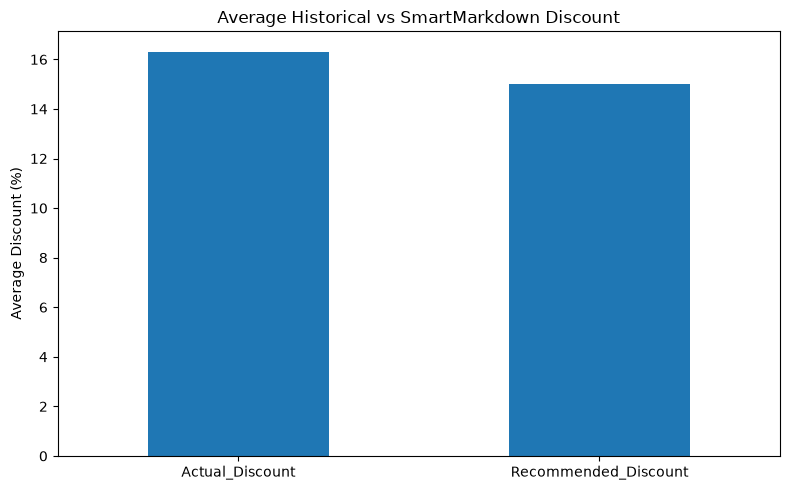

In [168]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

valid_backtest[
    [
        "Actual_Discount",
        "Recommended_Discount"
    ]
].mean().plot(
    kind="bar"
)

plt.title("Average Historical vs SmartMarkdown Discount")

plt.ylabel("Average Discount (%)")

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../outputs/final/"
    "historical_vs_recommended_discount.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

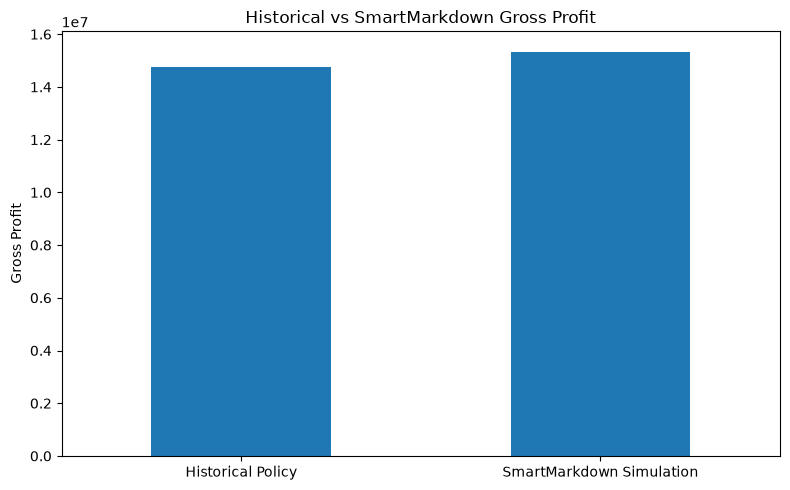

In [169]:
profit_comparison = pd.Series({
    "Historical Policy":
        historical_profit_no_replenishment,

    "SmartMarkdown Simulation":
        smartmarkdown_profit_no_replenishment
})

plt.figure(figsize=(8, 5))

profit_comparison.plot(
    kind="bar"
)

plt.title("Historical vs SmartMarkdown Gross Profit")
plt.ylabel("Gross Profit")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../outputs/final/"
    "historical_vs_smartmarkdown_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

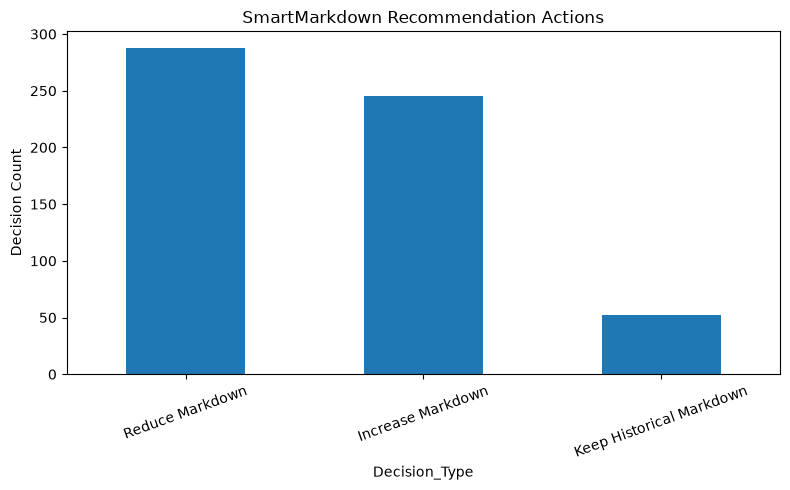

In [170]:
decision_counts = (
    valid_backtest[
        "Decision_Type"
    ]
    .value_counts()
)

plt.figure(figsize=(8, 5))

decision_counts.plot(
    kind="bar"
)

plt.title("SmartMarkdown Recommendation Actions")
plt.ylabel("Decision Count")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    "../outputs/final/"
    "recommendation_action_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

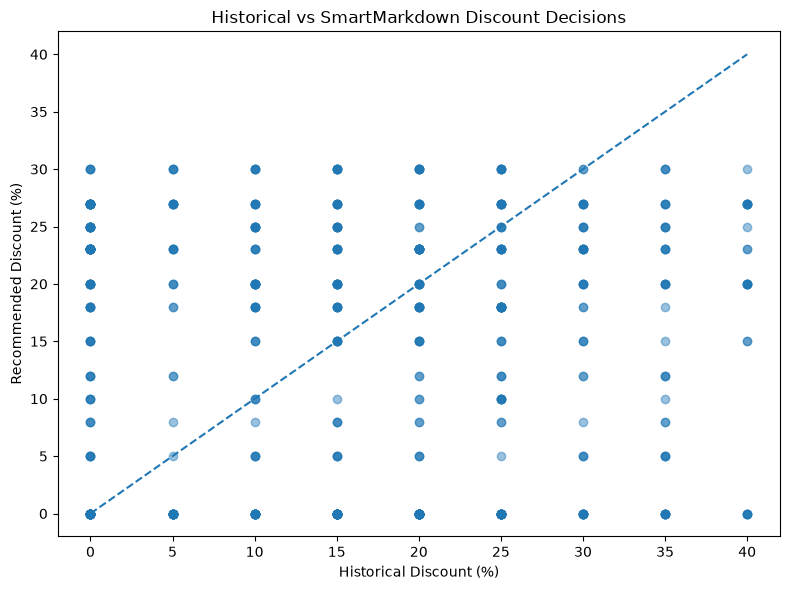

In [171]:
plt.figure(figsize=(8, 6))

plt.scatter(
    valid_backtest["Actual_Discount"],
    valid_backtest["Recommended_Discount"],
    alpha=0.45
)

max_discount = max(
    valid_backtest["Actual_Discount"].max(),
    valid_backtest["Recommended_Discount"].max()
)

plt.plot(
    [0, max_discount],
    [0, max_discount],
    linestyle="--"
)

plt.xlabel("Historical Discount (%)")
plt.ylabel("Recommended Discount (%)")

plt.title("Historical vs SmartMarkdown Discount Decisions")

plt.tight_layout()

plt.savefig(
    "../outputs/final/"
    "historical_vs_recommended_discount_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

- Above diagonal  : SmartMarkdown increases markdown
- Below diagonal  : SmartMarkdown reduces markdown
- On diagonal     : keeps historical markdown

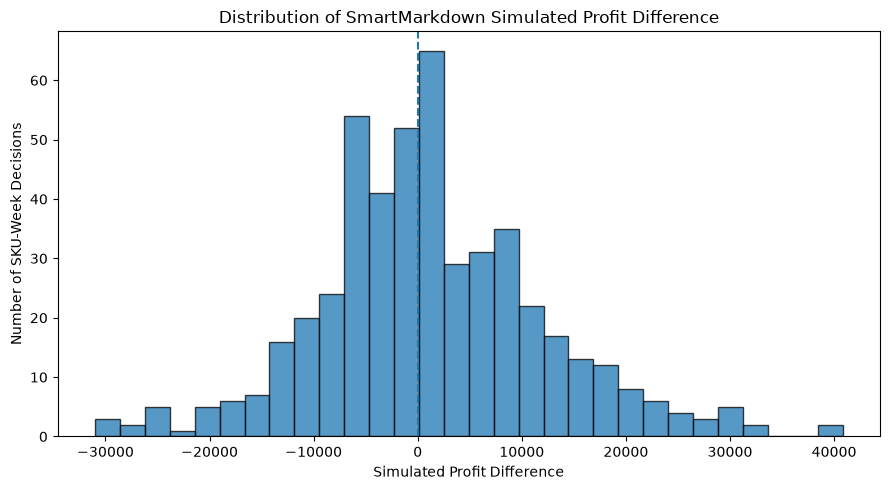

In [172]:
plt.figure(figsize=(9, 5))

plt.hist(
    no_replenishment_backtest[
        "Simulated_Profit_Difference"
    ],
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(0,linestyle="--")

plt.xlabel("Simulated Profit Difference")

plt.ylabel("Number of SKU-Week Decisions")

plt.title("Distribution of SmartMarkdown Simulated Profit Difference")

plt.tight_layout()

plt.savefig(
    "../outputs/final/"
    "simulated_profit_difference_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [173]:
discount_heatmap = (
    valid_backtest
    .pivot(
        index="SKU_ID",
        columns="Target_Week",
        values="Recommended_Discount"
    )
)

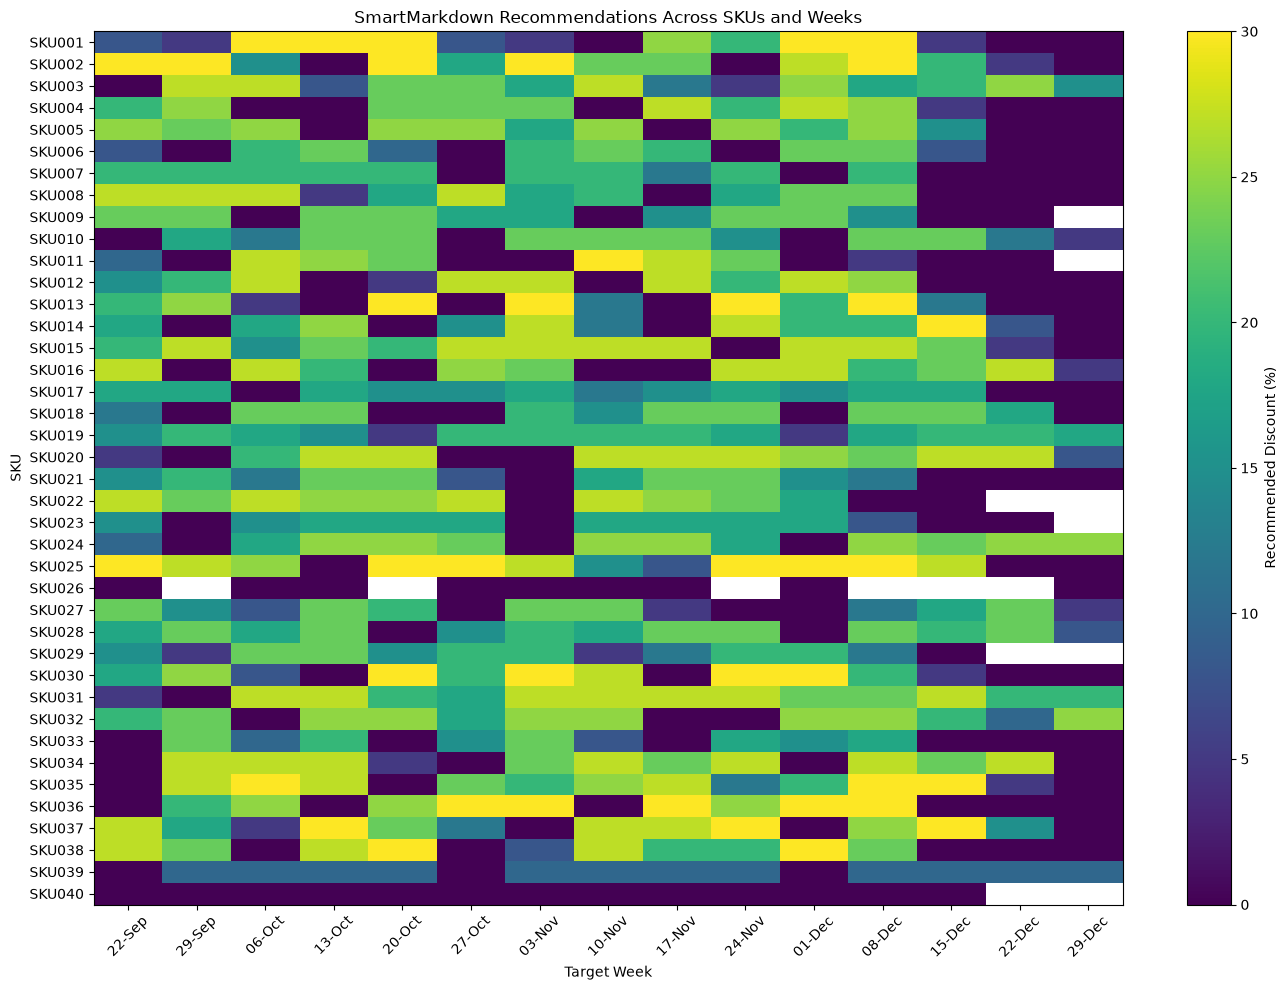

In [174]:
plt.figure(figsize=(14, 10))

plt.imshow(
    discount_heatmap,
    aspect="auto"
)

plt.colorbar(label="Recommended Discount (%)")

plt.yticks(range(len(discount_heatmap.index)),discount_heatmap.index)

plt.xticks(
    range(len(discount_heatmap.columns)),
    [
        d.strftime("%d-%b")
        for d in discount_heatmap.columns
    ],
    rotation=45
)

plt.xlabel("Target Week")
plt.ylabel("SKU")

plt.title("SmartMarkdown Recommendations Across SKUs and Weeks")

plt.tight_layout()

plt.savefig(
    "../outputs/final/"
    "sku_week_markdown_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 18. Final Model and Decision Engine Outputs

### Objective
Save the final demand model, recommendation outputs, business constraints and
supporting metadata required for downstream integration and future reuse.

The ML development scope is considered complete after these artifacts are saved
and documented.

In [175]:
decision_config = {
    "candidate_discounts": candidate_discounts,
    "target_sell_through_pct": 45,
    "max_allowed_discount": 30,
    "min_margin_pct": 35,
    "min_profit_retention_pct": 80,
    "min_conservative_profit_retention_pct": 75,
    "primary_backtest_profit_difference_pct": 3.93,
    "full_backtest_profit_difference_pct": 5.44
}

joblib.dump(
    decision_config,
    "../models/smartmarkdown_decision_config.joblib"
)

print("Decision configuration saved successfully.")

Decision configuration saved successfully.


In [176]:
joblib.dump(
    backtest_price_response_df,
    "../models/smartmarkdown_price_response.joblib"
)

print("Price-response artifact saved successfully.")

Price-response artifact saved successfully.


In [177]:
joblib.dump(
    cluster_mapping,
    "../models/smartmarkdown_cluster_mapping.joblib"
)

print("Cluster mapping saved successfully.")

Cluster mapping saved successfully.


In [178]:
portfolio_recommendation_df.to_csv(
    "../outputs/final/smartmarkdown_portfolio_recommendations.csv",
    index=False
)

print("Final portfolio recommendations saved.")

Final portfolio recommendations saved.


## 19. Final Conclusion

SmartMarkdown combines demand forecasting, SKU behavioural segmentation,
historical markdown-response estimation, prediction uncertainty and business
constraints to generate SKU-level markdown recommendations.

### Final Demand Model
Gradient Boosting was selected as the final demand forecasting model.

Test performance:

- MAE: 7.00
- RMSE: 9.76
- WAPE: 17.05%
- R²: 0.737

### Recommendation Engine
The decision engine evaluates multiple markdown scenarios and balances:

- expected demand
- inventory availability
- sell-through
- gross profit
- margin
- forecast uncertainty

The system can recommend increasing, reducing or maintaining markdown rather
than assuming that larger discounts are always preferable.

### Backtesting
On the full actionable test period, the simulated SmartMarkdown policy produced
a 5.44% higher aggregate gross profit than the observed historical policy.

Because 16.24% of historical decisions contained target-week replenishment,
a stricter no-replenishment comparison was used as the primary evaluation.

On 490 comparable SKU-week decisions:

- Historical Gross Profit: ₹14,760,674.65
- Simulated SmartMarkdown Gross Profit: ₹15,341,191.56
- Simulated Gross Profit Difference: +₹580,516.91
- Simulated Gross Profit Difference: +3.93%
These results represent simulated counterfactual policy estimates and should not
be interpreted as causal business uplift.

### Final Outcome
The completed ML system provides an interpretable and configurable framework for
profit-aware retail markdown optimization.

## 20. Recommendation Engine Packaging

### Objective
Move the finalized markdown recommendation logic from the development notebook
into a reusable Python module.

This separates experimentation from production-ready logic and makes the
SmartMarkdown engine easier to reuse during downstream integration.

In [179]:
decision_config = {
    "candidate_discounts": candidate_discounts,

    "target_sell_through_pct": 45,
    "max_allowed_discount": 30,

    "min_margin_pct": 35,
    "min_profit_retention_pct": 80,
    "min_conservative_profit_retention_pct": 75,

    "prediction_intervals": {
        "low": {
            "max_demand": 25,
            "lower_residual": -5.53,
            "upper_residual": 9.25
        },

        "medium": {
            "max_demand": 50,
            "lower_residual": -12.56,
            "upper_residual": 17.99
        },

        "high": {
            "lower_residual": -19.91,
            "upper_residual": 27.43
        }
    },

    "primary_backtest_profit_difference_pct": 3.93,
    "full_backtest_profit_difference_pct": 5.44
}

In [180]:
joblib.dump(
    decision_config,
    "../models/smartmarkdown_decision_config.joblib"
)

print("Final decision configuration saved.")

Final decision configuration saved.


In [181]:
import os

final_artifacts = [
    "../models/smartmarkdown_demand_model.joblib",
    "../models/smartmarkdown_demand_model_metadata.joblib",
    "../models/smartmarkdown_decision_config.joblib",
    "../models/smartmarkdown_price_response.joblib",
    "../models/smartmarkdown_cluster_mapping.joblib"
]

for file in final_artifacts:

    status = (
        "Available"
        if os.path.exists(file)
        else "Missing"
    )

    print(
        os.path.basename(file),
        "->",
        status
    )

smartmarkdown_demand_model.joblib -> Available
smartmarkdown_demand_model_metadata.joblib -> Available
smartmarkdown_decision_config.joblib -> Available
smartmarkdown_price_response.joblib -> Available
smartmarkdown_cluster_mapping.joblib -> Available


In [182]:
reloaded_demand_model = joblib.load(
    "../models/smartmarkdown_demand_model.joblib"
)

reloaded_metadata = joblib.load(
    "../models/smartmarkdown_demand_model_metadata.joblib"
)

reloaded_config = joblib.load(
    "../models/smartmarkdown_decision_config.joblib"
)

print("Model:",reloaded_metadata["model_name"])

print("Feature Count:",reloaded_metadata["feature_count"])

print("Candidate Discounts:",reloaded_config["candidate_discounts"])

Model: GradientBoostingRegressor
Feature Count: 33
Candidate Discounts: [0, 5, 8, 10, 12, 15, 18, 20, 23, 25, 27, 30]


In [185]:
X_smoke_test = (
    latest_sku_rows[
        latest_sku_rows["SKU_ID"] == "SKU003"
    ][feature_cols]
)

smoke_test_prediction = (reloaded_demand_model.predict(X_smoke_test)[0])

print("Reloaded Model Prediction:",round(smoke_test_prediction, 2))

Reloaded Model Prediction: 44.16


## 21. Final Technical Handover Checklist

The SmartMarkdown ML development has been completed and validated.

### Final Components

- Raw and processed datasets
- Data validation and EDA notebooks
- Feature engineering pipeline
- Final Gradient Boosting demand model
- Model metadata
- SKU behavioural clustering
- SKU markdown-response estimates
- Adaptive prediction intervals
- Markdown scenario simulation
- Business profitability constraints
- Reusable markdown recommendation engine
- Portfolio-level recommendations
- Historical backtesting
- Final KPI and visualization outputs
- Saved model and decision-engine artifacts

### Final Model Artifacts

- `smartmarkdown_demand_model.joblib`
- `smartmarkdown_demand_model_metadata.joblib`
- `smartmarkdown_decision_config.joblib`
- `smartmarkdown_price_response.joblib`
- `smartmarkdown_cluster_mapping.joblib`

### Primary Backtest Result

On the replenishment-free test subset of 490 SKU-week decisions,
SmartMarkdown produced a simulated gross-profit difference of **+3.93%**
relative to the observed historical policy.

The result represents a simulated counterfactual policy estimate rather than
causal business uplift.

## 21. API-Ready Decision Engine

### Objective
Separate the finalized prediction and markdown-decision logic from the
development notebook so that it can be reused by an API or other application.

The notebook remains responsible for model development and analysis, while the
`src` module contains only the reusable inference logic required after training.

## 22. Final Project Cleanup and Handover Readiness

### Objective
Prepare the SmartMarkdown project for team handover by verifying that the final
datasets, model artifacts, outputs and reusable source components are organized
and available.

This step does not change the modelling logic. It ensures that the completed
work can be understood, reused and integrated by other team members.

In [186]:
import os

required_folders = [
    "../data/raw",
    "../data/processed",
    "../models",
    "../notebooks",
    "../outputs/final",
    "../src"
]

for folder in required_folders:
    print(
        folder,
        "->",
        "Available"
        if os.path.exists(folder)
        else "Missing"
    )

../data/raw -> Available
../data/processed -> Available
../models -> Available
../notebooks -> Available
../outputs/final -> Available
../src -> Available


In [187]:
final_files = [
    "../data/raw/SmartMarkdown_Data_Dev_2024_2025.xlsx",
    "../data/processed/smartmarkdown_feature_engineered.csv",

    "../models/smartmarkdown_demand_model.joblib",
    "../models/smartmarkdown_demand_model_metadata.joblib",
    "../models/smartmarkdown_decision_config.joblib",
    "../models/smartmarkdown_price_response.joblib",
    "../models/smartmarkdown_cluster_mapping.joblib",

    "../outputs/final/smartmarkdown_portfolio_recommendations.csv",
    "../outputs/final/smartmarkdown_backtest_results.csv",
    "../outputs/final/smartmarkdown_no_replenishment_backtest.csv",
    "../outputs/final/smartmarkdown_final_kpis.csv"
]

for file in final_files:

    print(
        os.path.basename(file),
        "->",
        "Available"
        if os.path.exists(file)
        else "Missing"
    )

SmartMarkdown_Data_Dev_2024_2025.xlsx -> Available
smartmarkdown_feature_engineered.csv -> Available
smartmarkdown_demand_model.joblib -> Available
smartmarkdown_demand_model_metadata.joblib -> Available
smartmarkdown_decision_config.joblib -> Available
smartmarkdown_price_response.joblib -> Available
smartmarkdown_cluster_mapping.joblib -> Available
smartmarkdown_portfolio_recommendations.csv -> Available
smartmarkdown_backtest_results.csv -> Available
smartmarkdown_no_replenishment_backtest.csv -> Available
smartmarkdown_final_kpis.csv -> Available


In [188]:
project_manifest = pd.DataFrame({
    "Artifact": [
        "Raw Retail Dataset",
        "Feature Engineered Dataset",
        "Demand Forecast Model",
        "Model Metadata",
        "Decision Configuration",
        "SKU Price Response",
        "SKU Cluster Mapping",
        "Portfolio Recommendations",
        "Backtest Results",
        "No-Replenishment Backtest",
        "Final KPI Summary"
    ],

    "Purpose": [
        "Original two-year synthetic retail dataset",
        "Model-ready features used for forecasting",
        "Final Gradient Boosting demand forecasting pipeline",
        "Feature names and model performance metadata",
        "Candidate discounts and decision constraints",
        "Historical SKU markdown-response information",
        "Behavioural segment assigned to each SKU",
        "Latest SKU-level markdown recommendations",
        "Historical SmartMarkdown policy simulation",
        "Primary comparable backtest subset",
        "Final technical and business KPIs"
    ]
})

display(project_manifest)

,Artifact,Purpose
0,Raw Retail Dataset,Original two-year synthetic retail dataset
1,Feature Engineered Dataset,Model-ready features used for forecasting
2,Demand Forecast Model,Final Gradient Boosting demand forecasting pip...
3,Model Metadata,Feature names and model performance metadata
4,Decision Configuration,Candidate discounts and decision constraints
5,SKU Price Response,Historical SKU markdown-response information
6,SKU Cluster Mapping,Behavioural segment assigned to each SKU
7,Portfolio Recommendations,Latest SKU-level markdown recommendations
8,Backtest Results,Historical SmartMarkdown policy simulation
9,No-Replenishment Backtest,Primary comparable backtest subset


In [189]:
project_manifest.to_csv(
    "../outputs/final/smartmarkdown_project_manifest.csv",
    index=False
)

print("Project manifest saved.")

Project manifest saved.


## 23. Knowledge Transfer – SmartMarkdown Architecture

### Project Objective
SmartMarkdown is an ML-driven retail markdown optimization system that recommends
SKU-level discount decisions while balancing demand, inventory movement and
profitability.

The system does not directly predict the discount.

Instead, it:

1. forecasts next-week demand,
2. estimates SKU markdown response,
3. simulates multiple candidate discounts,
4. evaluates profit and inventory impact,
5. applies business constraints,
6. recommends the smallest feasible markdown that achieves the inventory objective.

### Component Summary

**Data Validation**
Checks data quality, inventory consistency, pricing logic and target reliability.

**Feature Engineering**
Creates historical demand, pricing, inventory, event and customer-interest features.

**Demand Forecasting**
Predicts next-week latent demand for each SKU.

**SKU Clustering**
Groups products with similar demand, volatility, inventory and markdown behaviour.

**Markdown Response**
Estimates how historical demand changes as discount levels change.

**Prediction Uncertainty**
Adds lower and upper demand bounds around the point forecast.

**Scenario Simulation**
Evaluates multiple candidate discounts such as 0%, 5%, 8%, 10%, ..., 30%.

**Business Constraints**
Protects minimum margin and acceptable profit retention.

**Recommendation Engine**
Selects the smallest feasible markdown that achieves the sell-through objective.

**Backtesting**
Compares simulated SmartMarkdown policy outcomes against historical decisions.

### Final Demand Model

The final next-week demand forecasting model is a
**Gradient Boosting Regressor**.

Final test performance:

- MAE: 7.00
- RMSE: 9.76
- WAPE: 17.05%
- R²: 0.737

Gradient Boosting was selected after comparison with:

- 4-week moving-average baseline
- Linear Regression
- Ridge Regression
- Random Forest
- Gradient Boosting

### Example: SKU003

Current State:

- Baseline next-week demand forecast: 44.16 units
- Closing inventory: 118 units
- Current discount: 0%
- MRP: ₹1,999
- Unit cost: ₹940

The engine simulates multiple discounts.

At 0% discount:
- Projected sell-through: 37.43%
- Expected gross profit: ₹46,768.68

At 15% discount:
- Projected sell-through: 46.07%
- Expected gross profit: ₹41,270.94
- Profit retention: 88.24%
- Margin: 44.68%

At 18% discount:
- Projected sell-through: 47.80%
- Profit retention: 84.32%

Both 15% and 18% satisfy the business constraints and achieve the sell-through
target.

The engine recommends **15%** because it is the smallest feasible markdown that
achieves the inventory objective while preserving more profit.

### Backtest Result

The primary backtest used 490 SKU-week decisions with no target-week replenishment.

Historical Gross Profit:
₹14,760,674.65

Simulated SmartMarkdown Gross Profit:
₹15,341,191.56

Simulated Profit Difference:
₹580,516.91

Simulated Profit Difference:
+3.93%

This is interpreted as a simulated counterfactual policy estimate rather than
causal business uplift.